# CAMS auxiliary data

GRS takes the state of the atmosphere at the time of the image from the
[CAMS global atmospheric composition forecasts](https://ads.atmosphere.copernicus.eu/datasets/cams-global-atmospheric-composition-forecasts)
of the Copernicus Atmosphere Monitoring Service, distributed by the Atmosphere Data Store (ADS):

| CAMS variables | use in GRS |
|---|---|
| surface pressure `sp`, mean sea level pressure `msl` | Rayleigh scattering (pressure at the surface, or at the DEM altitude) |
| total columns of O$_3$ `gtco3`, NO$_2$ `tcno2`, CO `tcco`, CH$_4$ `tc_ch4`, water vapour `tcwv` | gaseous transmittance |
| aerosol optical depth at 469, 550, 670, 865 and 1240 nm `aod<wl>` | choice of the aerosol model, first guess of the AOT |
| AOD at 550 nm of each aerosol species (`duaod550`, `ssaod550`...) | information |
| 10 m wind `u10`, `v10` | roughness of the water surface (sunglint) |

This notebook shows how to download these data, how they are stored (one global file per day, in a
`YYYY/MM/DD` tree) and what GRS reads from them, on a Sentinel-2 image of 2026-03-09 over Lake Geneva
(tile 31TGM).

## 1. Access to the Atmosphere Data Store

1. Create an account on the [ADS](https://ads.atmosphere.copernicus.eu) and accept the licence of the
   dataset (*Download* tab of the dataset page).
2. Copy your API key from your ADS profile into `~/.cdsapirc`:

   ```
   url: https://ads.atmosphere.copernicus.eu/api
   key: <your-personal-access-token>
   ```
3. Install the client: `pip install "cdsapi>=0.7"` (installed with GRS).

The download cells below are not run in this documentation (`DOWNLOAD = False`): set `DOWNLOAD = True`
to run them.

In [1]:
import os
import calendar
import warnings

import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

import cdsapi
from osgeo import gdal
import GRSdriver
import grs

gdal.UseExceptions()
warnings.filterwarnings('ignore', message='Dataset has no geotransform')   # rasterio, footprint masks

opj = os.path.join
print(f'grs:       {grs.__version__}')
print(f'GRSdriver: {GRSdriver.__version__}')

grs:       3.1.0
GRSdriver: 2.0.3


In [2]:
# settings: edit the paths to run the notebook on your own data
DOWNLOAD = False   # True to send the requests to the ADS

l1c_file = ('/data/satellite/Sentinel-2/L1C/31TGM/2026/03/09/'
            'S2B_MSIL1C_20260309T103019_N0512_R108_T31TGM_20260309T143722.SAFE')
# CAMS archive, one global file per day:
#   <cams_dir>/YYYY/MM/DD/YYYY-MM-DD-cams-global-atmospheric-composition-forecasts.nc
# (dates up to March 2026 also in the older monthly files <cams_dir>/cams_forecast_YYYY-MM.nc)
cams_dir = '/data/cams/world'

## 2. Download the data of one image

{class}`~grs.cams.CamsProduct` knows the date and the footprint of an image: its method
{meth}`~grs.cams.CamsProduct.cams_download` requests the forecasts of the day (runs of 00:00 and
12:00 UTC, lead times 0 to 9 h) over the footprint enlarged by 1°, and writes them into the
`YYYY/MM/DD` archive of `dir`, next to the global file of the day:
`<dir>/YYYY/MM/DD/YYYY-MM-DD-cams-global-atmospheric-composition-forecasts<suffix>.nc`. Without
`cams_file`, `CamsProduct` reads the global file of the day if it exists (as here), else this file of
the area (`filepath`), downloaded by {meth}`~grs.cams.CamsProduct.load` if needed; GRS does the same
when no CAMS file is given, with the archive of `path: cams` of the configuration. The image is opened
at 60 m with GRSdriver, which is enough to get its date and footprint.

In [3]:
l1c = GRSdriver.Sentinel2Driver(l1c_file, resolution=60)
l1c.load_product()
prod = grs.Product(l1c.prod)

cams_image = grs.CamsProduct(prod.raster, dir=cams_dir, suffix='_31TGM')
print('date:             ', cams_image.date_str)
print('area [N, W, S, E]:', np.round(cams_image.area, 2))
print('file read:        ', cams_image.filepath)
print('file downloaded:  ', cams_image.download_filepath)
if DOWNLOAD:
    cams_image.cams_download()

date:              2026-03-09
area [N, W, S, E]: [47.92  4.58 44.9   8.07]
file read:         /data/cams/world/2026/03/09/2026-03-09-cams-global-atmospheric-composition-forecasts.nc
file downloaded:   /data/cams/world/2026/03/09/2026-03-09-cams-global-atmospheric-composition-forecasts_31TGM.nc


## 3. Download global daily files

To process many images, it is simpler to download the forecasts over the whole globe once, and to give
GRS the file of the date of each image. The files are stored one per day in a `YYYY/MM/DD` tree:

```
/data/cams/world/2026/09/09/2026-09-09-cams-global-atmospheric-composition-forecasts.nc
```

A daily file holds the runs of 00:00 and 12:00 UTC (dimension `forecast_reference_time`) with lead
times 0, 3, 6 and 9 h (`forecast_period`), on the 0.4° grid of CAMS (about 170 MB). The script
[`ecmwf/download_cams_cds_day.py`](https://github.com/CNES/GRSprocessor/tree/main/ecmwf) of the
repository downloads into this tree the file of the date three days before the current date; run it
every day (e.g. with cron) to keep the archive up to date:

```bash
python ecmwf/download_cams_cds_day.py forecast /data/cams/world
```

The function below does the same for any date ({py:func}`grs.cams.cams_daily_file` gives the path
of the file of a date). For long past periods, one file per month
(`download_month`, older archive `cams_forecast_YYYY-MM.nc`) needs fewer requests to the ADS.

In [4]:
from grs.cams import CAMS_DATASET, cams_daily_file


def request(date_range):
    """ADS request of the variables used by GRS (global, runs of 00 and 12 UTC, lead times 0-9 h)."""
    return {'date': date_range,
            'type': 'forecast',
            'format': 'netcdf',
            'variable': cams_image.variable,     # variables used by GRS
            'time': ['00:00', '12:00'],
            'leadtime_hour': ['0', '3', '6', '9']}


def download_day(date, odir):
    """Download the global CAMS forecasts of one day into the YYYY/MM/DD tree of `odir`."""
    filepath = cams_daily_file(date, odir)       # global file of the day
    if not os.path.exists(filepath):
        os.makedirs(os.path.dirname(filepath), exist_ok=True)
        day = os.path.basename(filepath)[:10]
        cdsapi.Client().retrieve(CAMS_DATASET, request(f'{day}/{day}'), filepath)
    return filepath


def download_month(year, month, odir):
    """Download the global CAMS forecasts of one month into <odir>/cams_forecast_YYYY-MM.nc."""
    ndays = calendar.monthrange(year, month)[1]
    filepath = opj(odir, f'cams_forecast_{year:04d}-{month:02d}.nc')
    if not os.path.exists(filepath):
        os.makedirs(odir, exist_ok=True)
        cdsapi.Client().retrieve(CAMS_DATASET, request(f'{year:04d}-{month:02d}-01/{year:04d}-{month:02d}-{ndays:02d}'),
                                 filepath)
    return filepath


if DOWNLOAD:
    for day in ('2026-09-08', '2026-09-09', '2026-09-10'):
        print(download_day(day, cams_dir))

### CAMS file of an image

The file of an image is the daily file of its acquisition date. For the dates of the older archive
(monthly files, up to March 2026), `cams_file_of` falls back on the file of the month:

In [5]:
def cams_file_of(date, cams_dir=cams_dir):
    """CAMS file of a date: daily file of the YYYY/MM/DD tree, else monthly file; None if none exists."""
    date = np.datetime64(date, 'D').item()
    for filepath in (cams_daily_file(date, cams_dir), opj(cams_dir, f'cams_forecast_{date:%Y-%m}.nc')):
        if os.path.exists(filepath):
            return filepath
    return None


cams_file = cams_file_of(cams_image.date_str)   # image of this tutorial: 2026-03-09
print('image', cams_image.date_str, '->', cams_file)

for day in ('2026-09-09', '2025-08-01'):
    print(day, '->', cams_file_of(day))

image 2026-03-09 -> /data/cams/world/2026/03/09/2026-03-09-cams-global-atmospheric-composition-forecasts.nc
2026-09-09 -> /data/cams/world/2026/09/09/2026-09-09-cams-global-atmospheric-composition-forecasts.nc
2025-08-01 -> /data/cams/world/cams_forecast_2025-08.nc


## 4. What GRS reads from a CAMS file

{meth}`~grs.cams.CamsProduct.load` selects the forecasts of the day of the image, interpolates them
to the time of the acquisition and crops them to the footprint (about 0.4° resolution, i.e. a few
CAMS cells over a Sentinel-2 tile). The wind module `wind` is computed from `u10` and `v10`.

In [6]:
cams = grs.CamsProduct(prod.raster, cams_file=cams_file)
cams.load()
cams.raster

<xarray.Dataset> Size: 28kB
Dimensions:                  (y: 12, x: 12)
Coordinates:
  * y                        (y) float64 96B 5.2e+06 5.19e+06 ... 5.09e+06
  * x                        (x) float64 96B 7e+05 7.099e+05 ... 8.098e+05
    forecast_period          timedelta64[ns] 8B 04:29:03
    forecast_reference_time  datetime64[ns] 8B 2026-03-09T06:01:16
    time                     datetime64[ns] 8B 2026-03-09T10:30:19
    spatial_ref              int64 8B 0
Data variables: (12/24)
    u10                      (y, x) float64 1kB -0.1576 -0.2883 ... -0.9386
    v10                      (y, x) float64 1kB 0.3256 0.2854 ... 0.7241 0.8746
    t2m                      (y, x) float64 1kB 286.9 286.5 ... 275.1 274.2
    msl                      (y, x) float64 1kB 1.022e+05 ... 1.025e+05
    sp                       (y, x) float64 1kB 9.811e+04 ... 8.098e+04
    bcaod550                 (y, x) float64 1kB 0.00793 0.007975 ... 0.004368
    ...                       ...
    gtco3                    (y, x) float64 1kB 0.007838 0.00781 ... 0.007701
    tcwv                     (y, x) float64 1kB 14.49 14.05 13.57 ... 5.53 5.143
    amaod550                 (y, x) float64 1kB 0.00471 0.00514 ... 0.003848
    niaod550                 (y, x) float64 1kB 0.03503 0.03695 ... 0.02219
    soaod550                 (y, x) float64 1kB 0.02092 0.02152 ... 0.008714
    wind                     (y, x) float64 1kB 0.3617 0.4056 ... 1.162 1.283
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-03-11T17:03 GRIB to CDM+CF via cfgrib-0.9.1...

Maps of the CAMS variables over the tile (aerosol optical depth by species and in total,
meteorology, gas columns, wind components):

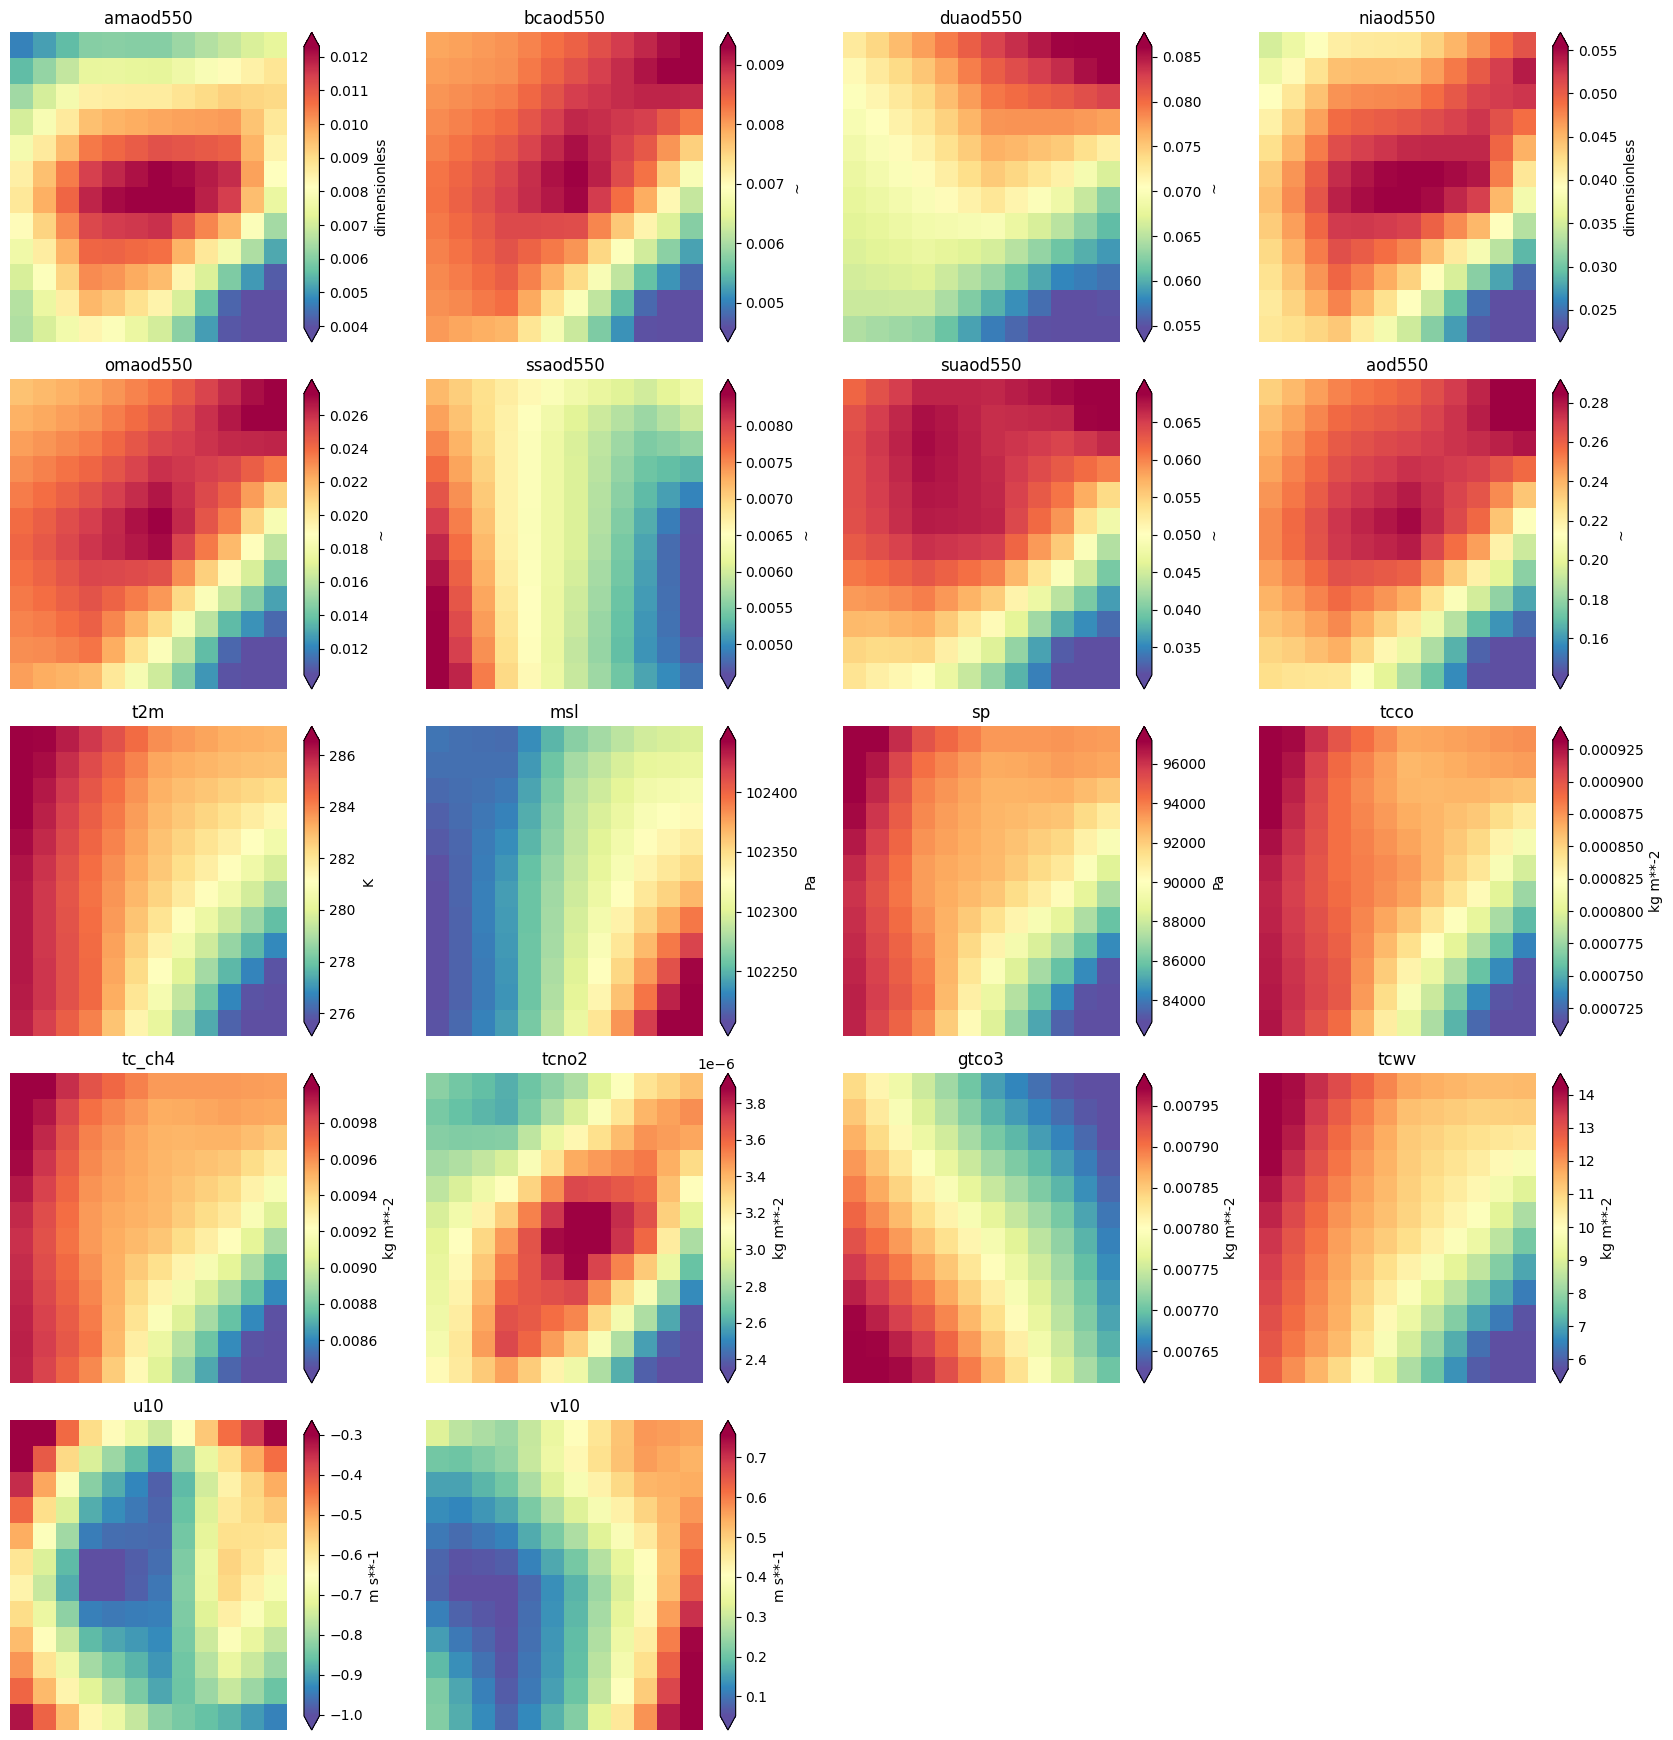

In [7]:
fig, axs = cams.plot_params(cmap='Spectral_r')

### Spectral aerosol optical depth

GRS compares the spectral shape of the CAMS AOD, normalized at 550 nm, with those of the OPAC aerosol
models of its look-up tables to choose the aerosol model (see {doc}`../../methods`). The Ångström
exponent $\alpha$ of the CAMS spectrum, between 469 and 865 nm, indicates the size of the particles
(small $\alpha$: coarse particles such as dust or sea salt).

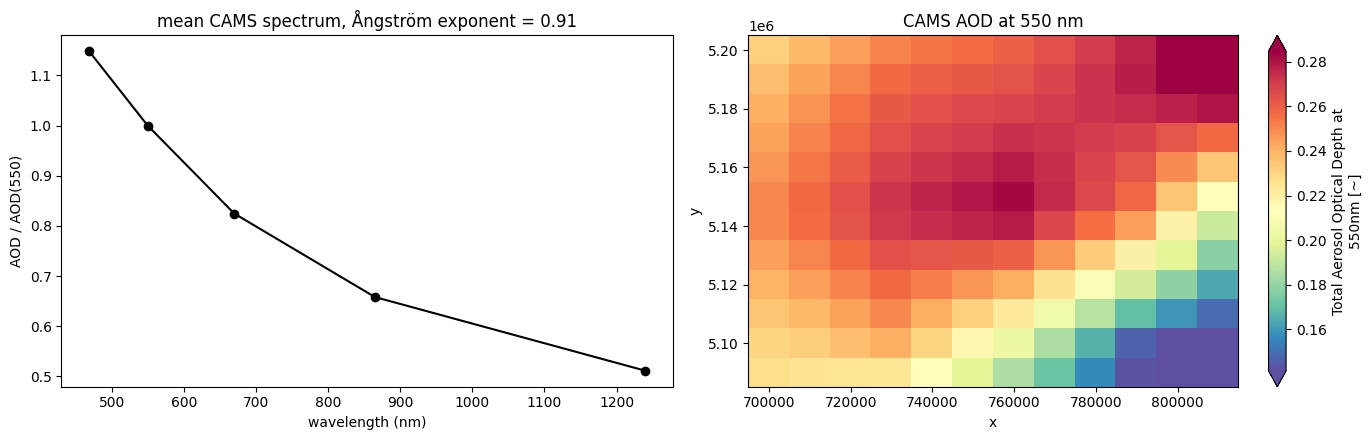

In [8]:
aod = cams.cams_aod.mean(['x', 'y'])
alpha = -np.log(aod.sel(wl=865) / aod.sel(wl=469)) / np.log(865 / 469)

fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
(aod / aod.sel(wl=550)).plot(ax=axs[0], marker='o', color='black')
axs[0].set(ylabel='AOD / AOD(550)', xlabel='wavelength (nm)',
           title=f'mean CAMS spectrum, Ångström exponent = {float(alpha):.2f}')
cams.raster.aod550.plot.imshow(ax=axs[1], cmap='Spectral_r', robust=True)
axs[1].set_title('CAMS AOD at 550 nm')
plt.tight_layout()

### Wind over the image

The CAMS wind sets the roughness of the water surface, i.e. the width of the sunglint pattern
(Cox and Munk slope distribution). Overlay on the true-colour image (top-of-atmosphere reflectance):

Text(0.5, 1.0, 'CAMS 10 m wind, 2026-03-09')

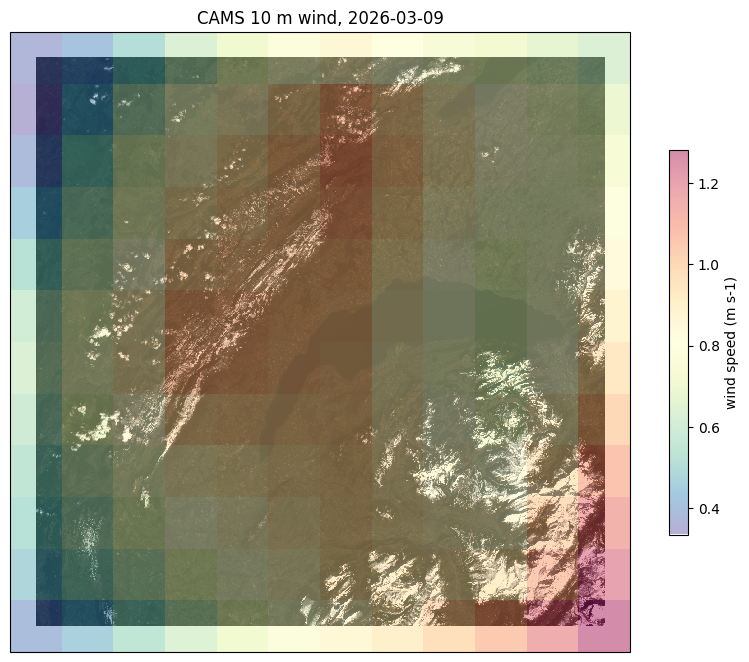

In [9]:
epsg = prod.raster.rio.crs.to_epsg()   # UTM zone of the tile, e.g. 32631
proj = ccrs.UTM(epsg % 100, southern_hemisphere=epsg // 100 == 327)
fig, ax = plt.subplots(figsize=(10, 10), subplot_kw={'projection': proj})
prod.raster.bands.sel(wl=[665, 560, 490], method='nearest').plot.imshow(
    rgb='wl', robust=True, ax=ax, transform=proj)
cams.raster.wind.plot.imshow(ax=ax, transform=proj, alpha=0.45, cmap='Spectral_r',
                             cbar_kwargs={'shrink': 0.5, 'label': 'wind speed (m s-1)'})
ax.set_title(f'CAMS 10 m wind, {cams.date_str}')

## 5. Use in GRS

Give the CAMS file of the image to the processing, from the command line or from Python:

```bash
grs S2B_MSIL1C_20260309T103019_N0512_R108_T31TGM_20260309T143722.SAFE \
    --cams_file /data/cams/world/2026/03/09/2026-03-09-cams-global-atmospheric-composition-forecasts.nc
```

```python
process = grs.Process()
process.execute(l1c_file, cams_file=cams_file_of(cams_image.date_str), resolution=20)
```

The CAMS data used are exported in the `ancillary` group of the output product (see {doc}`../../usage`).